In [1]:

!pip install -q datasets scikit-learn matplotlib


In [2]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import json
import os

from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU available: []


In [3]:

dataset = load_dataset("rajistics/indian_food_images")

print(dataset)
print("\nClass names:")
class_names = dataset["train"].features["label"].names

for i, name in enumerate(class_names):
    print(i, name)

num_classes = len(class_names)
print("\nTotal classes:", num_classes)


README.md:   0%|          | 0.00/660 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

data/train-00000-of-00001-dbae6752a5d31c(…): reconstructing file:   0%|          |  0.00B / 1.36GB            

data/train-00000-of-00001-dbae6752a5d31c(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-899c7c7e401d279(…): reconstructing file:   0%|          |  0.00B /  241MB            

data/test-00000-of-00001-899c7c7e401d279(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5328 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/941 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5328
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 941
    })
})

Class names:
0 burger
1 butter_naan
2 chai
3 chapati
4 chole_bhature
5 dal_makhani
6 dhokla
7 fried_rice
8 idli
9 jalebi
10 kaathi_rolls
11 kadai_paneer
12 kulfi
13 masala_dosa
14 momos
15 paani_puri
16 pakode
17 pav_bhaji
18 pizza
19 samosa

Total classes: 20


In [4]:

split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
val_dataset = split_dataset["test"]
test_dataset = dataset["test"]

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


Training images: 4262
Validation images: 1066
Test images: 941


In [6]:
import math

IMG_SIZE = 224
BATCH_SIZE = 32

def image_generator(hf_dataset):
    for item in hf_dataset:
        image = item["image"].convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE))

        image_array = np.asarray(image, dtype=np.float32)
        label = np.int32(item["label"])

        yield image_array, label


output_signature = (
    tf.TensorSpec(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        dtype=tf.float32
    ),
    tf.TensorSpec(shape=(), dtype=tf.int32)
)

train_tf = tf.data.Dataset.from_generator(
    lambda: image_generator(train_dataset),
    output_signature=output_signature
)

val_tf = tf.data.Dataset.from_generator(
    lambda: image_generator(val_dataset),
    output_signature=output_signature
)

test_tf = tf.data.Dataset.from_generator(
    lambda: image_generator(test_dataset),
    output_signature=output_signature
)

train_tf = (
    train_tf
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_tf = (
    val_tf
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_tf = (
    test_tf
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("All datasets are ready!")
print("Training batches:", math.ceil(len(train_dataset) / BATCH_SIZE))
print("Validation batches:", math.ceil(len(val_dataset) / BATCH_SIZE))
print("Test batches:", math.ceil(len(test_dataset) / BATCH_SIZE))

All datasets are ready!
Training batches: 134
Validation batches: 34
Test batches: 30


In [8]:
# 1. Define and compile the model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Rescaling(1./127.5, offset=-1), # Normalize MobileNetV2 inputs to [-1, 1]
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 2. Set up callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-6
    )
]

# 3. Fit the model
history = model.fit(
    train_tf,
    validation_data=val_tf,
    epochs=5,
    callbacks=callbacks
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
    134/Unknown 383s 2s/step - accuracy: 0.4277 - loss: 2.0302

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


134/134 ━━━━━━━━━━━━━━━━━━━━ 464s 3s/step - accuracy: 0.6176 - loss: 1.4300 - val_accuracy: 0.7711 - val_loss: 0.8462 - learning_rate: 0.0010
Epoch 2/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 429s 3s/step - accuracy: 0.8304 - loss: 0.6482 - val_accuracy: 0.8011 - val_loss: 0.6813 - learning_rate: 0.0010
Epoch 3/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 417s 3s/step - accuracy: 0.8827 - loss: 0.4835 - val_accuracy: 0.8180 - val_loss: 0.6219 - learning_rate: 0.0010
Epoch 4/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 424s 3s/step - accuracy: 0.9050 - loss: 0.3875 - val_accuracy: 0.8340 - val_loss: 0.5910 - learning_rate: 0.0010
Epoch 5/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 428s 3s/step - accuracy: 0.9254 - loss: 0.3251 - val_accuracy: 0.8283 - val_loss: 0.5891 - learning_rate: 0.0010


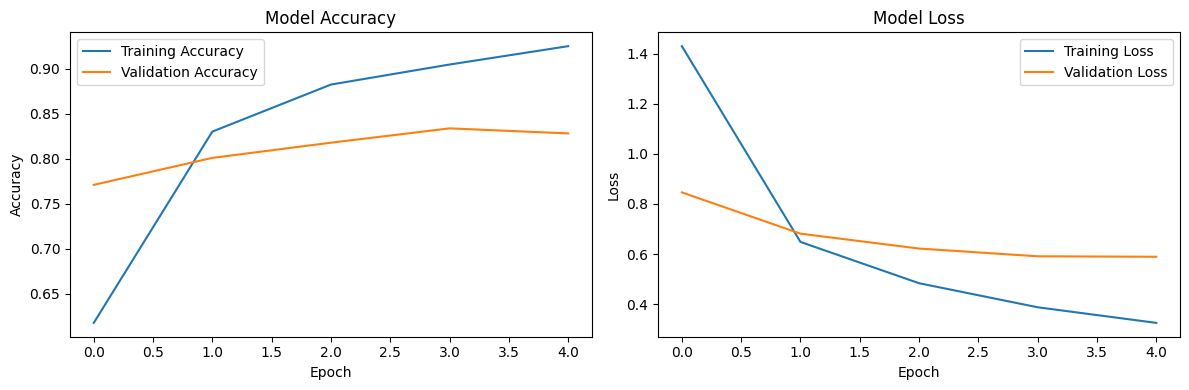

In [9]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [10]:

test_loss, test_accuracy = model.evaluate(test_tf)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")


30/30 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accuracy: 0.8193 - loss: 0.6739
Test Loss: 0.6739
Test Accuracy: 0.8193
Test Accuracy Percentage: 81.93%


Accuracy: 0.8193411264612115

Classification Report:

               precision    recall  f1-score   support

       burger       0.94      0.92      0.93        52
  butter_naan       0.79      0.79      0.79        53
         chai       0.90      0.91      0.90        57
      chapati       0.78      0.73      0.75        67
chole_bhature       0.85      0.83      0.84        54
  dal_makhani       0.78      0.71      0.74        55
       dhokla       0.75      0.87      0.81        53
   fried_rice       0.91      0.89      0.90        44
         idli       0.81      0.76      0.79        46
       jalebi       0.92      0.92      0.92        38
 kaathi_rolls       0.77      0.77      0.77        44
 kadai_paneer       0.75      0.83      0.79        54
        kulfi       0.73      0.82      0.78        40
  masala_dosa       0.78      0.89      0.83        47
        momos       0.93      0.86      0.89        49
   paani_puri       0.92      0.67      0.77        18
       pak

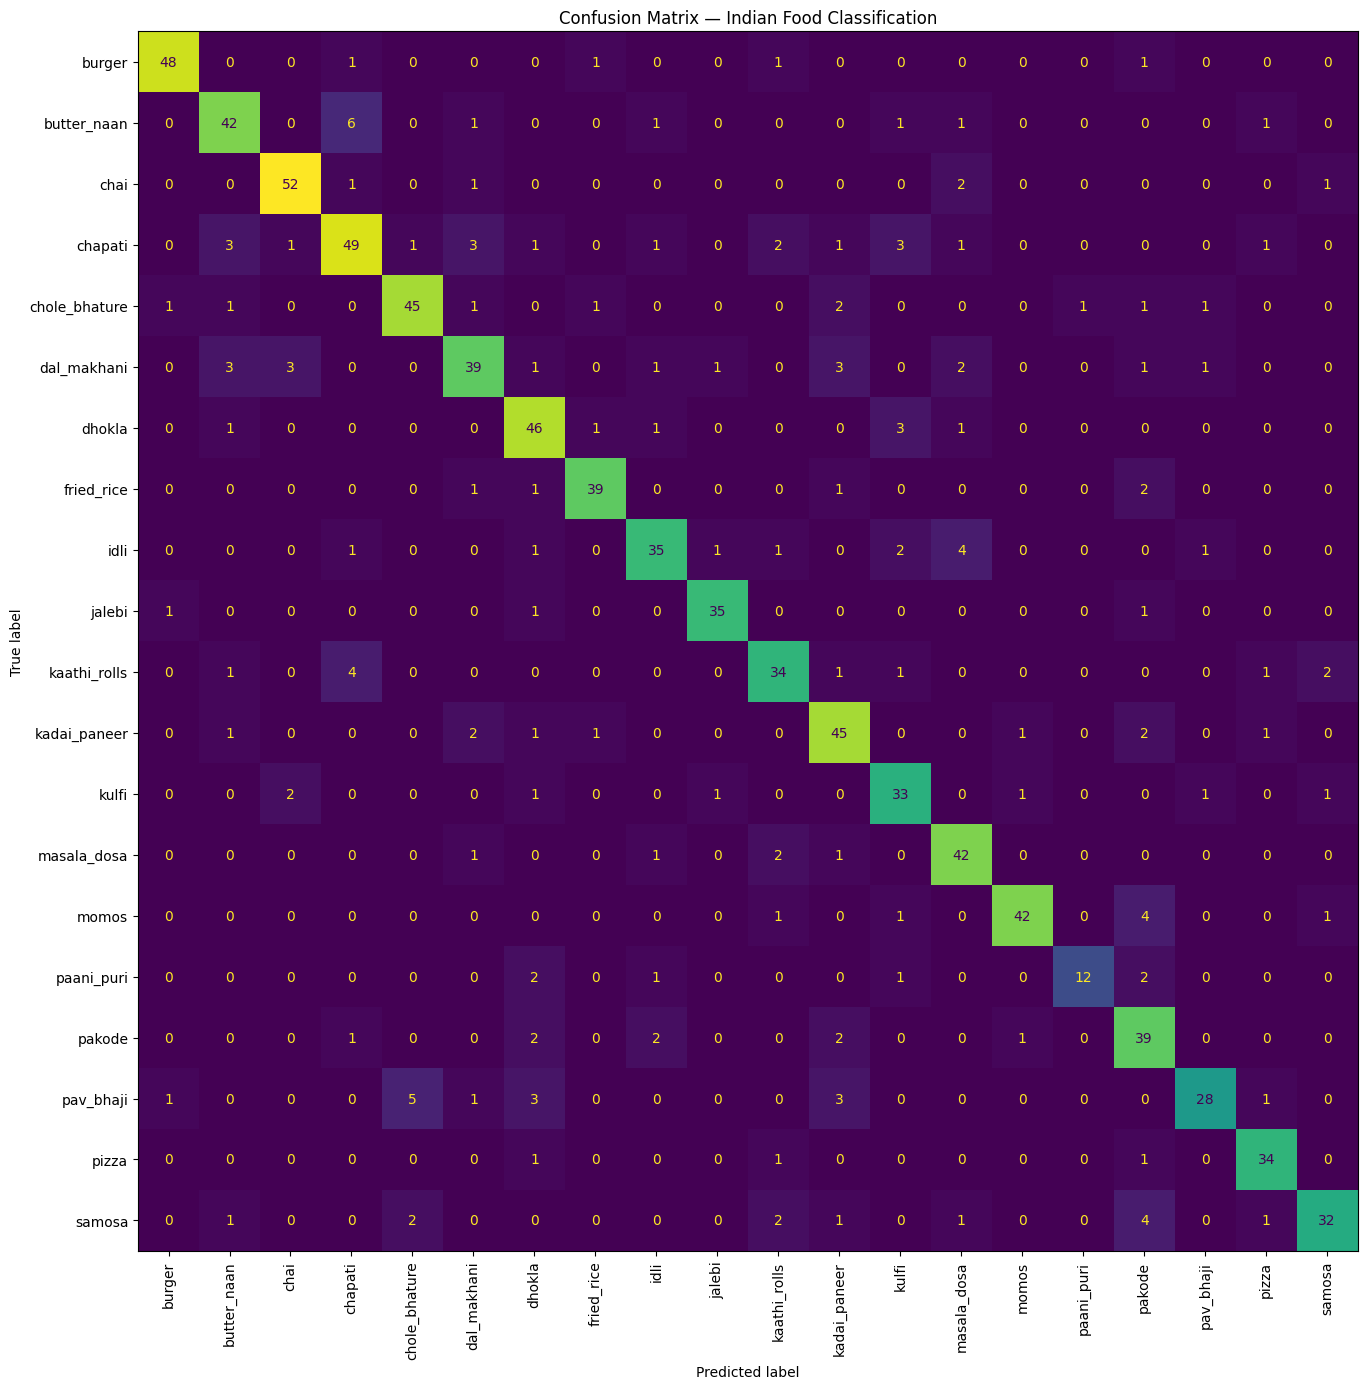

In [11]:

y_true = []
y_pred = []

for images, labels in test_tf:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy().tolist())
    y_pred.extend(predicted_labels.tolist())

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(14, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("Confusion Matrix — Indian Food Classification")
plt.tight_layout()
plt.show()


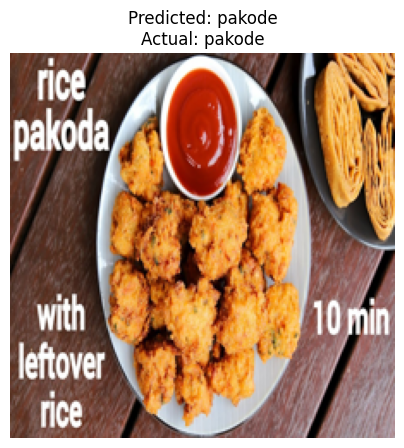

Predicted food: pakode
Actual food: pakode
Confidence: 56.22%


In [12]:

sample = test_dataset[0]

sample_image = sample["image"].convert("RGB")
display_image = sample_image.resize((IMG_SIZE, IMG_SIZE))

image_array = np.asarray(
    display_image,
    dtype=np.float32
)

image_batch = np.expand_dims(image_array, axis=0)

prediction = model.predict(image_batch, verbose=0)[0]

predicted_index = int(np.argmax(prediction))
actual_index = int(sample["label"])

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.axis("off")
plt.title(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[actual_index]}"
)
plt.show()

print("Predicted food:", class_names[predicted_index])
print("Actual food:", class_names[actual_index])
print(f"Confidence: {prediction[predicted_index] * 100:.2f}%")


In [13]:

model.save("indian_food_mobilenetv2.keras")

with open("class_names.json", "w") as file:
    json.dump(class_names, file, indent=4)

print("Model saved successfully!")
print("Class names saved successfully!")


Model saved successfully!
Class names saved successfully!


In [14]:

print("=" * 45)
print("INDIAN FOOD IMAGE CLASSIFICATION")
print("=" * 45)
print("Model: MobileNetV2 Transfer Learning")
print("Number of food classes:", num_classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print("Saved model: indian_food_mobilenetv2.keras")
print("=" * 45)


INDIAN FOOD IMAGE CLASSIFICATION
Model: MobileNetV2 Transfer Learning
Number of food classes: 20
Training images: 4262
Validation images: 1066
Test images: 941
Test accuracy: 81.93%
Saved model: indian_food_mobilenetv2.keras
